In [1]:
import scanpy as sc
import scanpy.external as sce

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad

from copy import deepcopy

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

import chronopack as cp


# Create AnnData object

In [212]:
sample_paths = [
    '../input/N701_scTHP1_K562_LPS_Split_RT_1_15min_Interval_Watchmaker_Replication//N701_scTHP1_K562_LPS_Split_RT_1_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N702_scTHP1_K562_LPS_Split_RT_2_15min_Interval_Watchmaker_Replication//N702_scTHP1_K562_LPS_Split_RT_2_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N703_scTHP1_K562_LPS_Split_RT_3_15min_Interval_Watchmaker_Replication//N703_scTHP1_K562_LPS_Split_RT_3_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N704_scTHP1_K562_LPS_Split_RT_4_15min_Interval_Watchmaker_Replication//N704_scTHP1_K562_LPS_Split_RT_4_15min_Interval_Watchmaker_Replication.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
]

adata = cp.io.read_time_tagged_dge(sample_paths, sample_names=['N701', 'N702', 'N703', 'N704'])
print(adata)


AnnData object with n_obs × n_vars = 5037 × 31580
    obs: 'FINAL TIME TAG', 'COUNTS'


/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/anndata/utils.py:311: UserWarning: X converted to numpy array with dtype float64
  warnings.warn(f"{name} converted to numpy array with dtype {arr.dtype}")


# QC & preprocessing

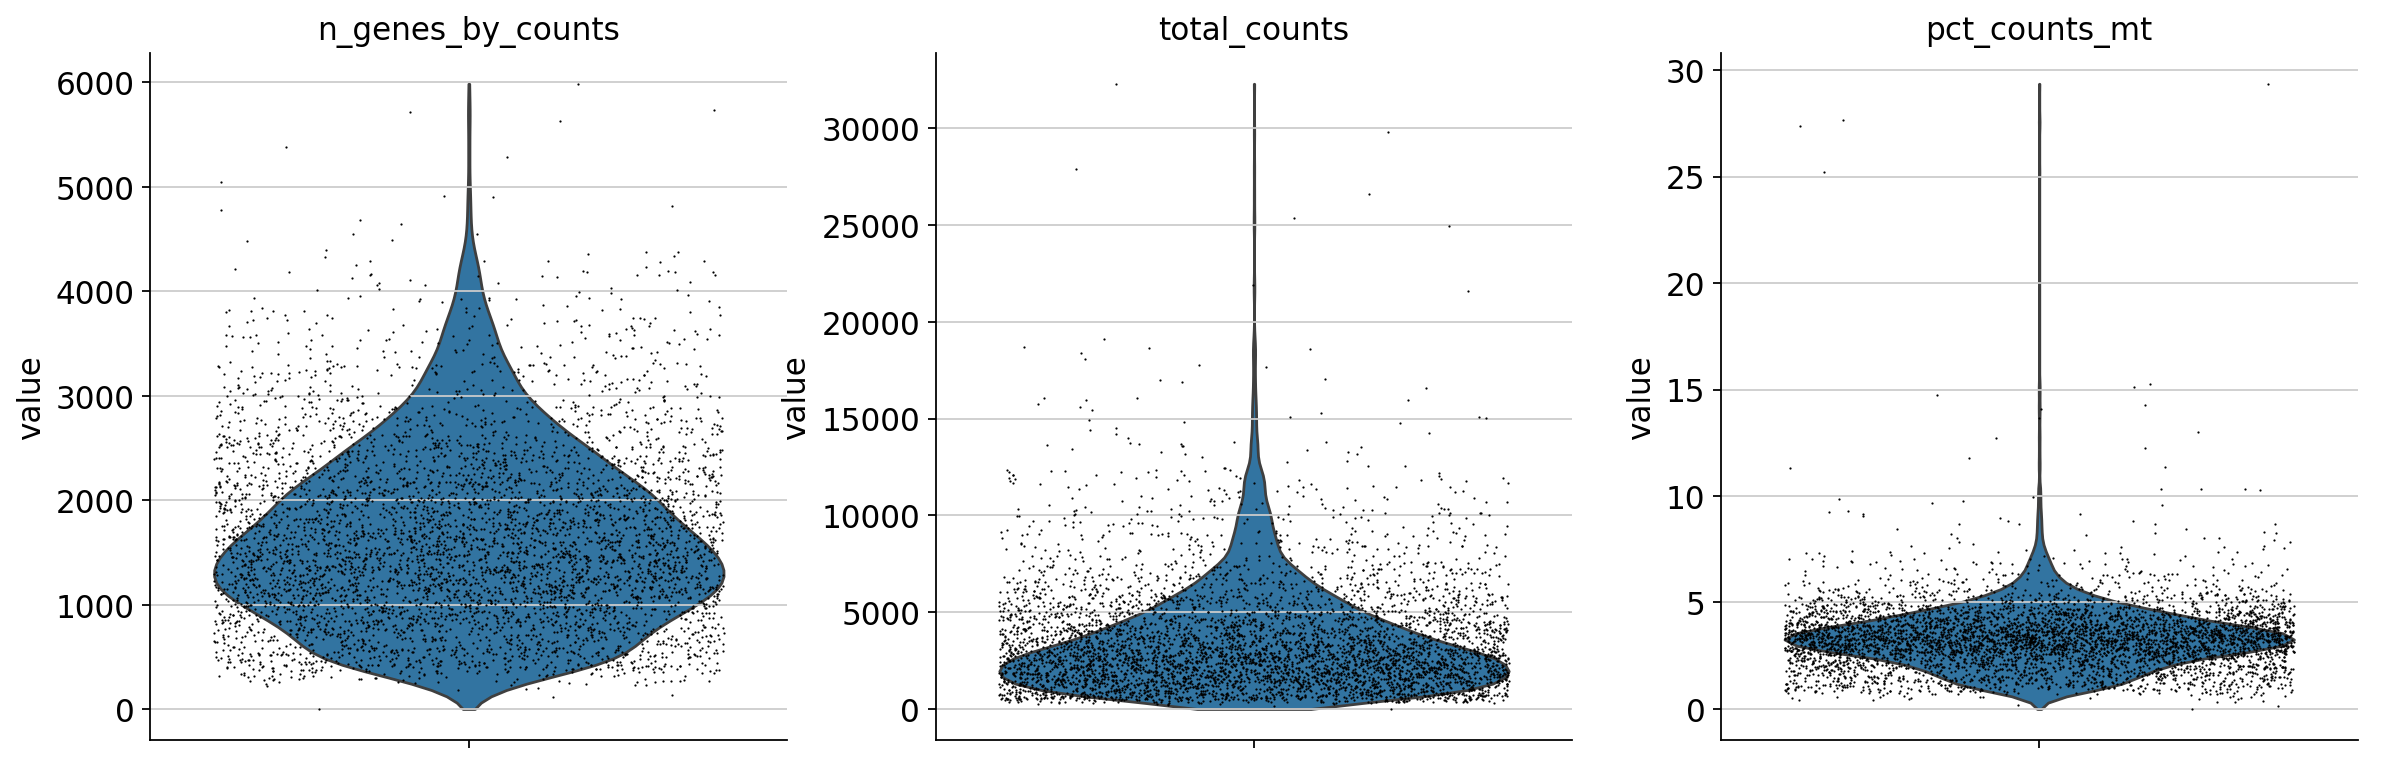

filtered out 114 cells that have less than 500 counts
filtered out 177 cells that have more than 10000 counts


/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


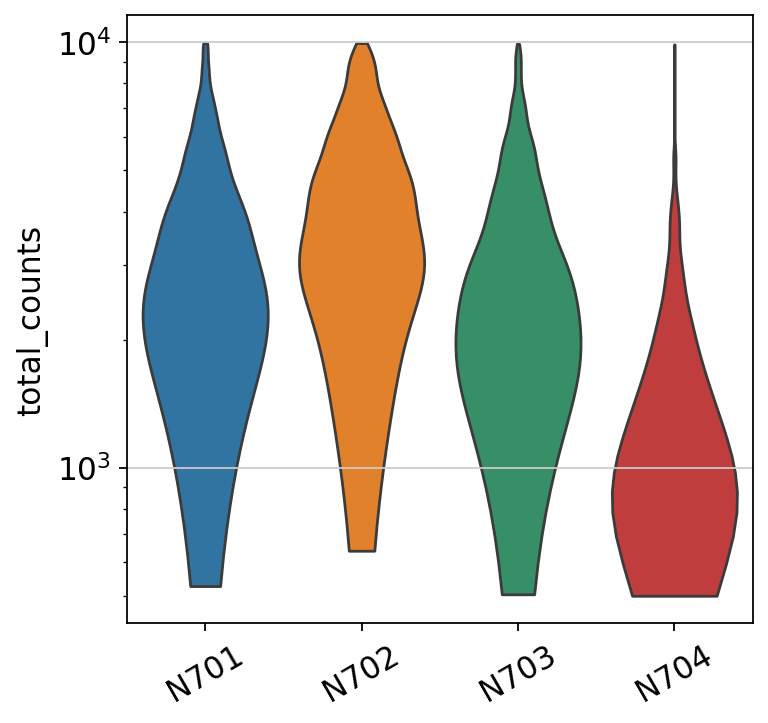

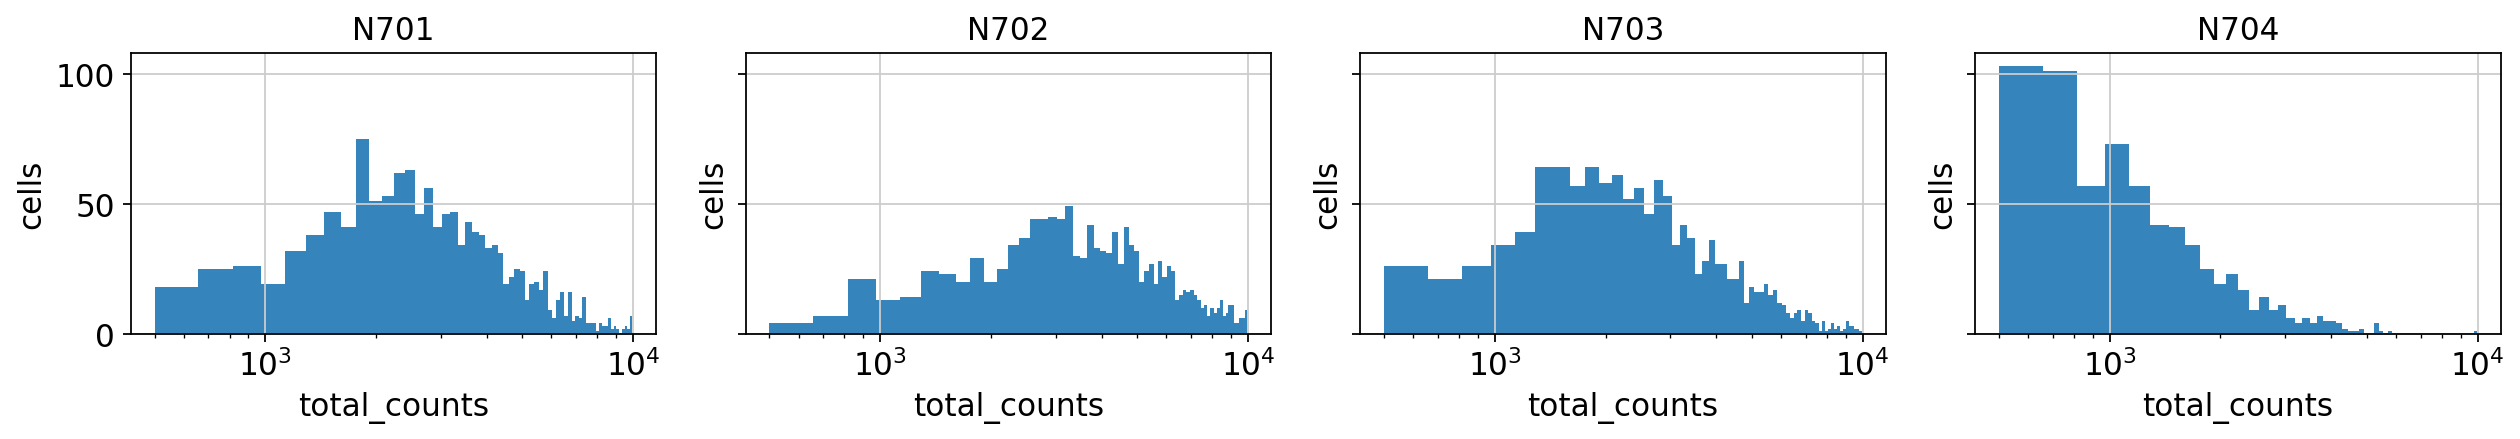

In [214]:
cp.io.annotate_qc_metrics(adata)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

adata = cp.io.filter_cells_by_qc(adata, min_counts=500, max_counts=10000, max_pct_mt=7.5)

sc.pl.violin(adata,
             keys='total_counts',
             groupby='sample',
             log=True,
             stripplot=False,
             rotation=30,
             multi_panel=False)

df = adata.obs[['sample','total_counts']].dropna().copy()
order = df['sample'].astype('category').cat.categories.tolist()

fig, axes = plt.subplots(1, len(order), figsize=(4*len(order), 3), sharex=True, sharey=True)
if len(order) == 1:
    axes = [axes]

bins = np.histogram_bin_edges(df['total_counts'].values, bins=60)
for ax, s in zip(axes, order):
    x = df.loc[df['sample'] == s, 'total_counts'].values
    ax.hist(x, bins=bins, alpha=0.9)
    ax.set_title(str(s))
    ax.set_xlabel('total_counts')
    ax.set_ylabel('cells')
    ax.set_xscale('log')

plt.tight_layout()
plt.show()


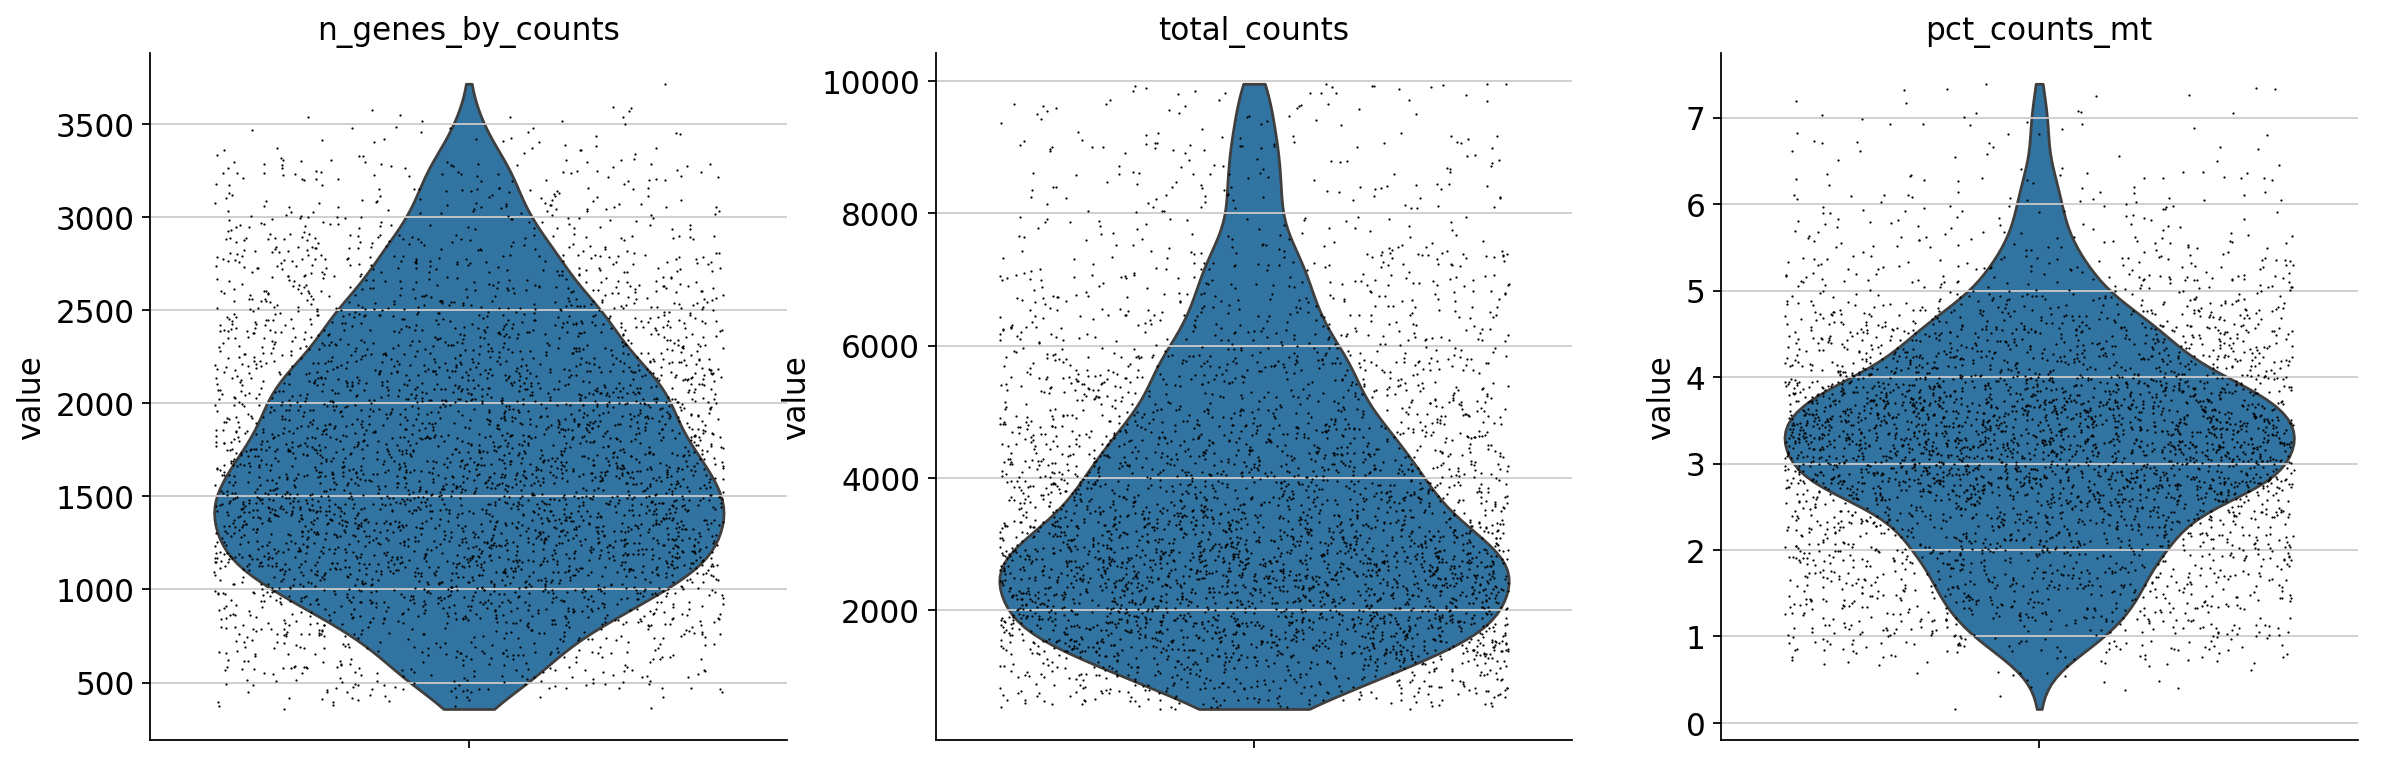

filtered out 54 cells that have less than 500 genes expressed


/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scanpy/preprocessing/_simple.py:170: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["n_genes"] = number


filtered out 9887 genes that are detected in less than 3 cells
AnnData object with n_obs × n_vars = 3953 × 21693
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_genes'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'sample_colors'


In [215]:
adata = adata[adata.obs['sample'] != 'N704', :].copy() # low quality RT batch
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

adata = cp.io.filter_cells_by_qc(adata, min_genes=500)
sc.pp.filter_genes(adata, min_cells=3)
print(adata)


In [216]:
sc.pp.scrublet(adata, batch_key="sample")
adata = adata[~adata.obs['predicted_doublet'], :]
print(adata.shape)


Running Scrublet
filtered out 4826 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.29
Detected doublet rate = 0.9%
Estimated detectable doublet fraction = 13.5%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 6.6%
filtered out 4328 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata

# Standard processing

In [217]:
cell_cycle_genes = [x.strip() for x in open('/new-stg/home/alex/ref/gene_sets/regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
cell_cycle_genes = [x for x in cell_cycle_genes if x in adata.var_names]


In [218]:
cp.io.initialize_expression_layers(adata, target_sum=1e4)


/new-stg/home/alex/.tmp/ipykernel_184474/3706083564.py:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata.layers['counts'] = adata.X.copy()


normalizing counts per cell
    finished (0:00:00)


In [343]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat",
    subset=False,
)

sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
adata_hvg = adata[:, (adata.var.highly_variable & ~np.isin(adata.var.index, list(cell_cycle_genes)))]


extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
calculating cell cycle phase
computing score 'S_score'
    finished: added
    'S_score', score of gene set (adata.obs).
    386 total control genes are used. (0:00:00)
computing score 'G2M_score'
    finished: added
    'G2M_score', score of gene set (adata.obs).
    427 total control genes are used. (0:00:00)
-->     'phase', cell cycle phase (adata.obs)


regressing out ['total_counts']


/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:04)


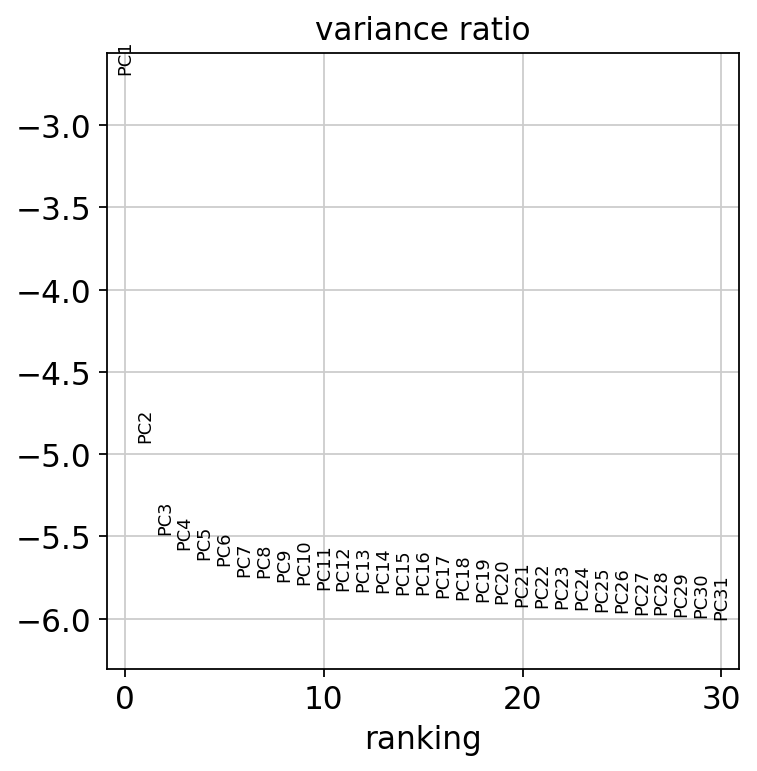

In [344]:
sc.pp.regress_out(adata_hvg, ['total_counts'])
sc.pp.scale(adata_hvg)
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=30, log=True)


computing neighbors
    using 'X_pca' with n_pcs = 4
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:08)
running Leiden clustering
    finished: found 2 clusters and added
    'leiden_unintegrated', the cluster labels (adata.obs, categorical) (0:00:00)


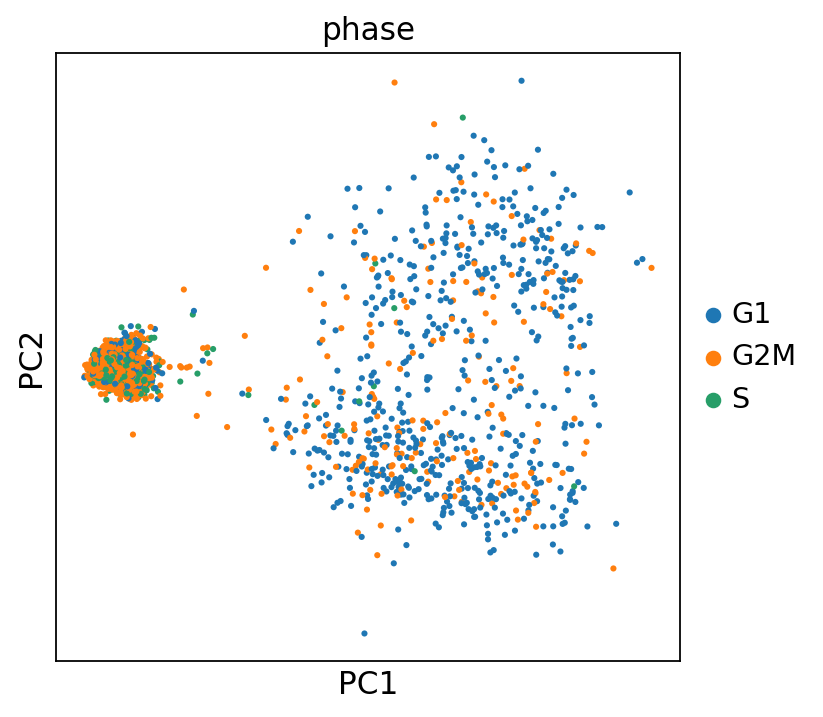

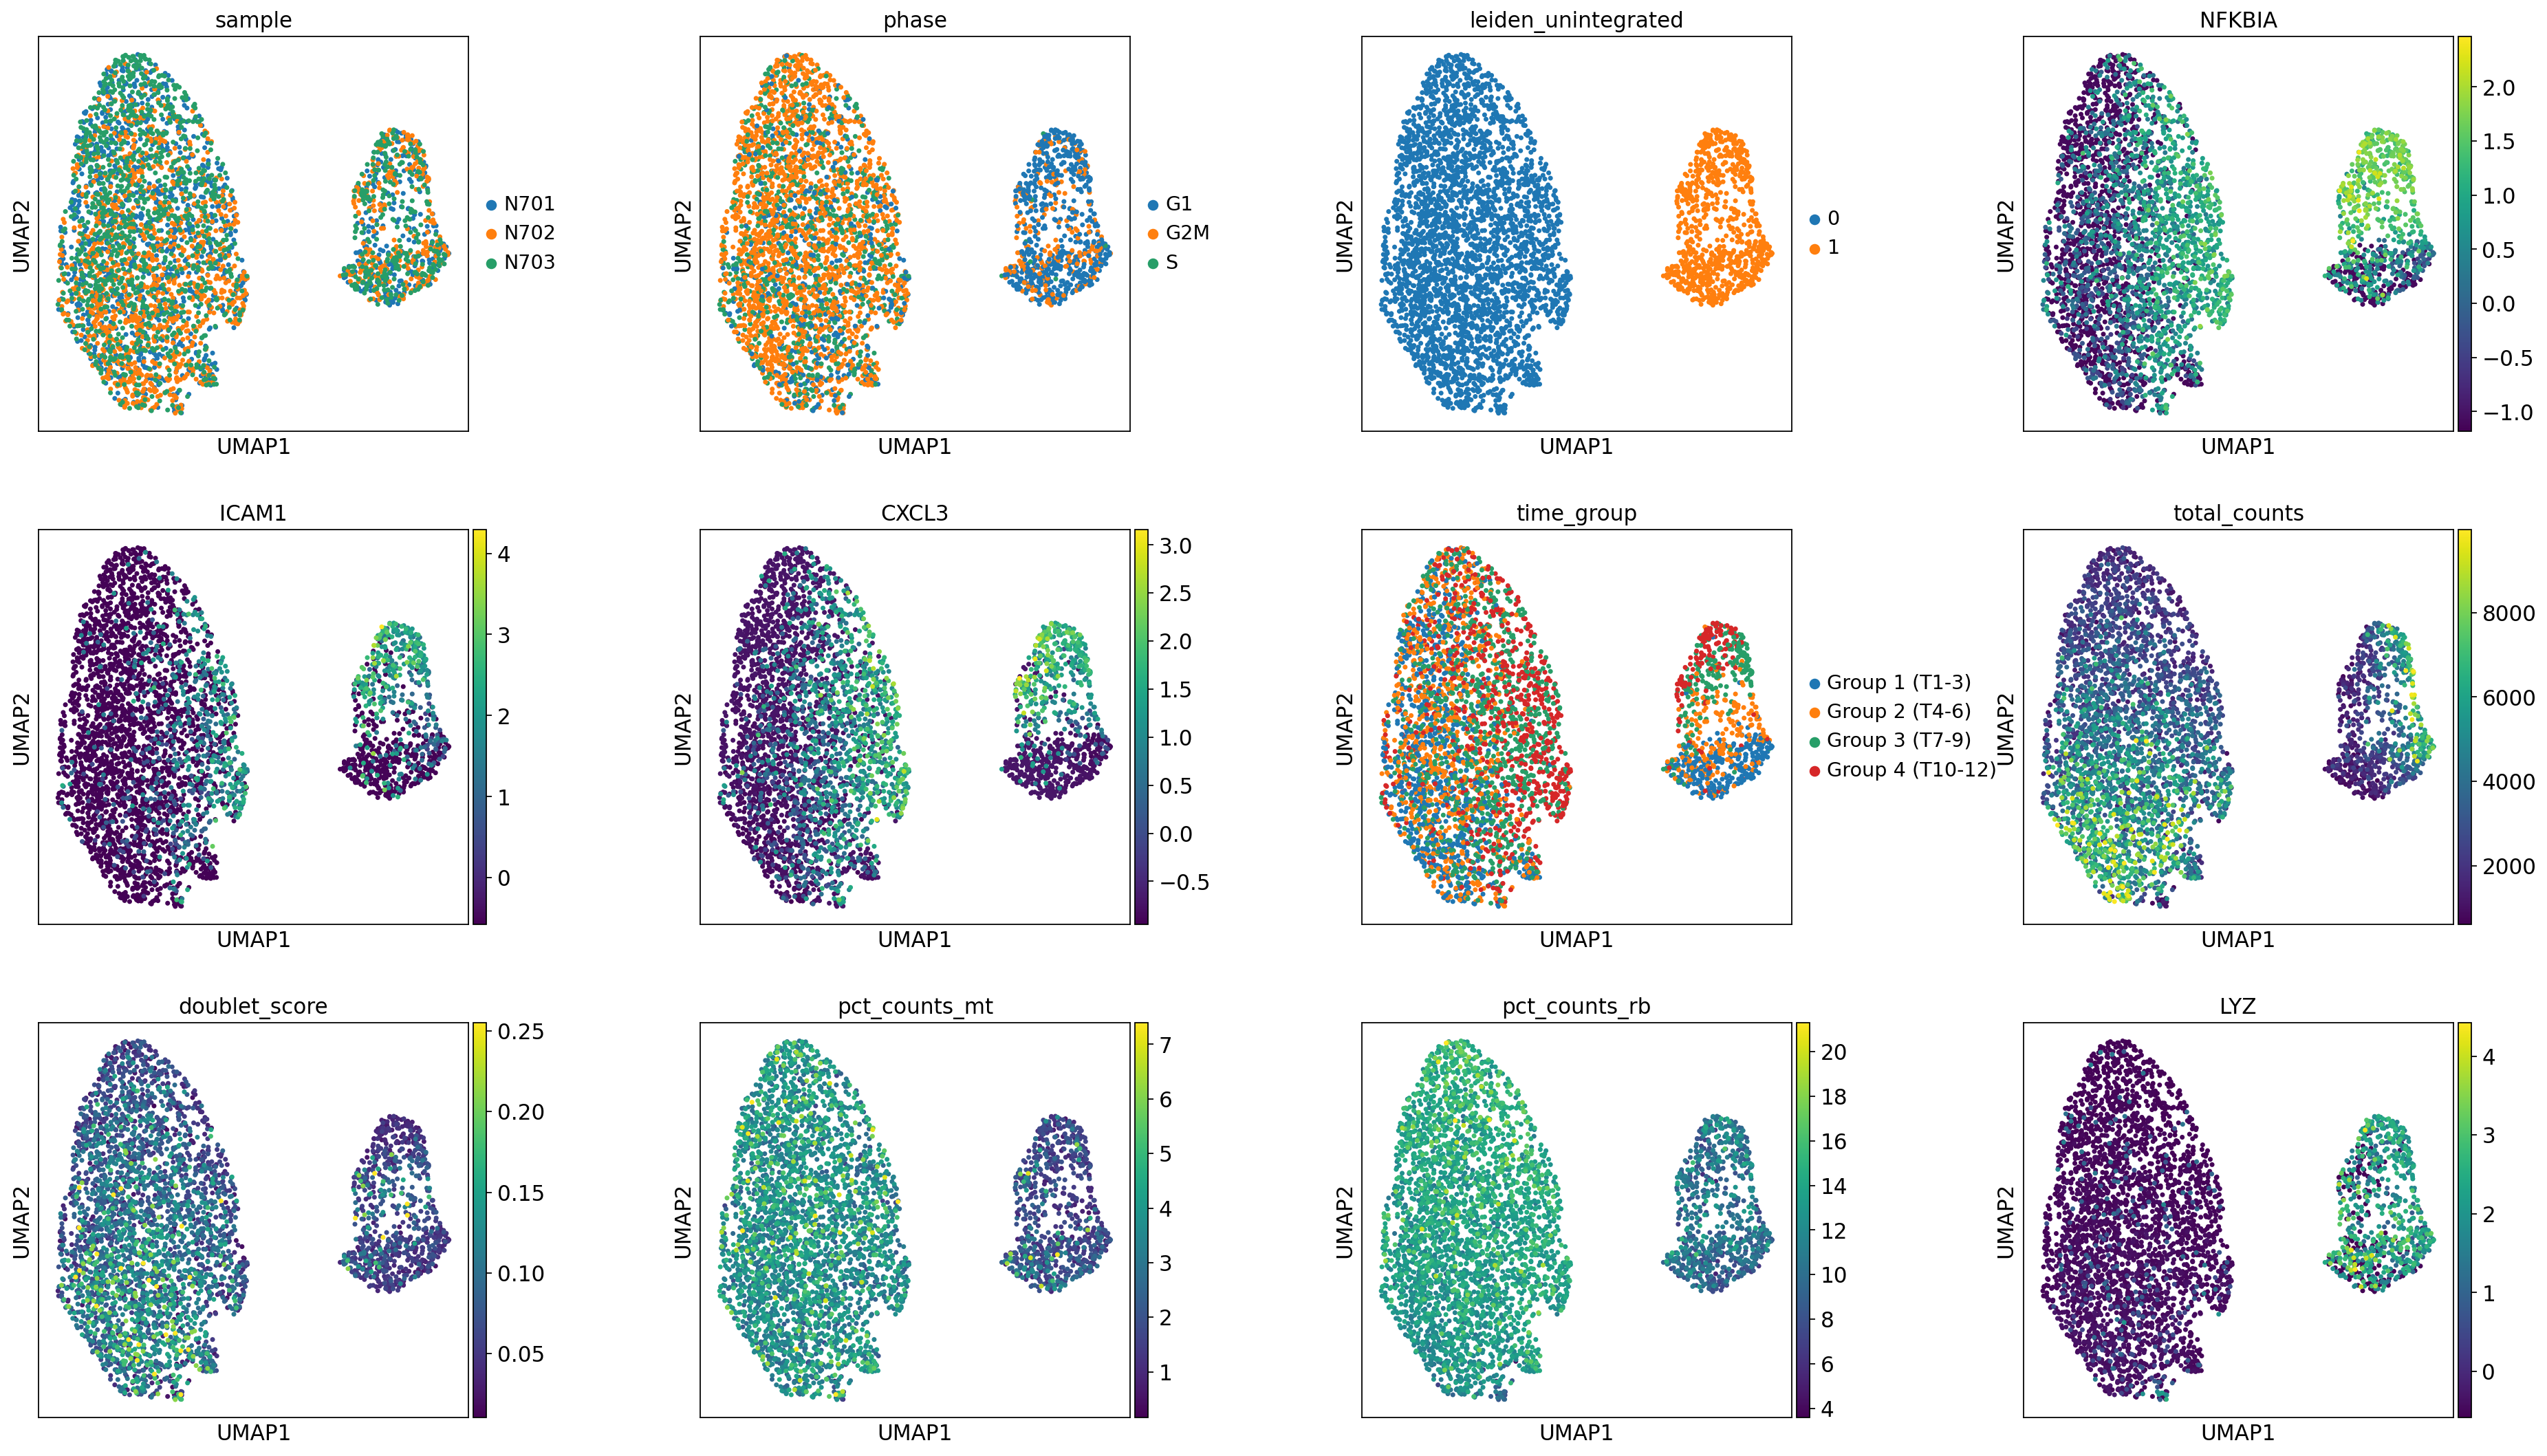

In [345]:
sc.pp.neighbors(adata_hvg, n_pcs=4, n_neighbors=30)
sc.tl.umap(adata_hvg)
sc.tl.leiden(adata_hvg, resolution=0.01, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata_hvg, color='phase')
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'leiden_unintegrated', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 
                         'doublet_score', 'pct_counts_mt', 'pct_counts_rb', 'LYZ'], wspace=0.4, size=40, ncols=4)


THP1 present: ['CD14', 'CD68', 'CD163', 'HLA-DRA', 'FCGR1A', 'MAFB', 'TNFAIP2']
THP1 missing: ['CD33', 'CD80', 'ITGAM']
K562 present: ['CD36', 'HBG1', 'CD69', 'IRF1']
K562 missing: ['CD34', 'CD43', 'GATA1', 'GYPA', 'TFRC']
computing score 'THP1_score'
    finished: added
    'THP1_score', score of gene set (adata.obs).
    345 total control genes are used. (0:00:00)
computing score 'K562_score'
    finished: added
    'K562_score', score of gene set (adata.obs).
    147 total control genes are used. (0:00:00)


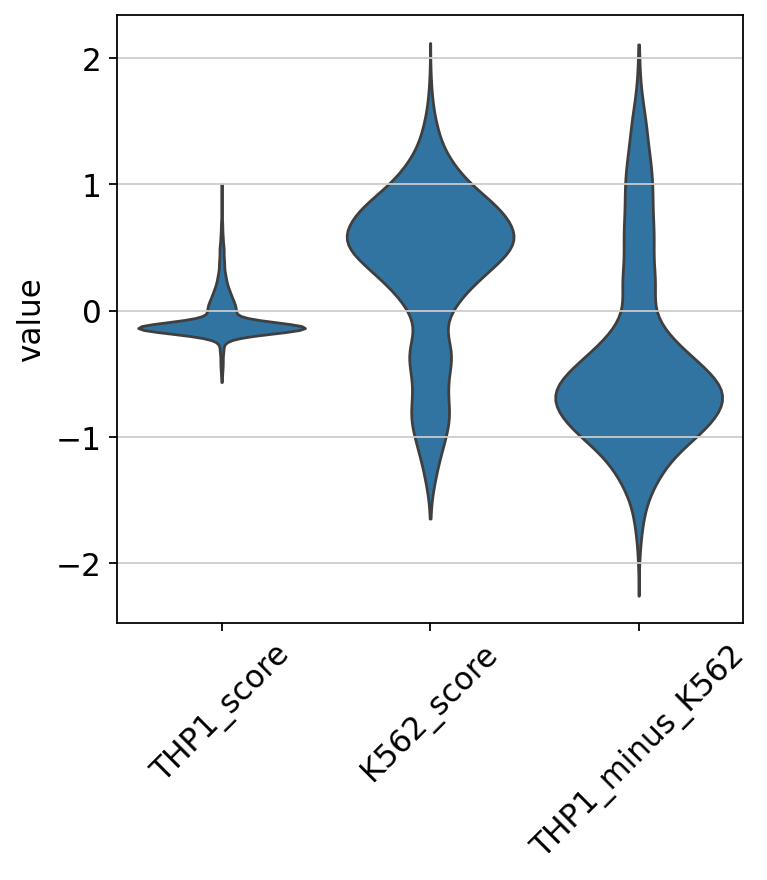

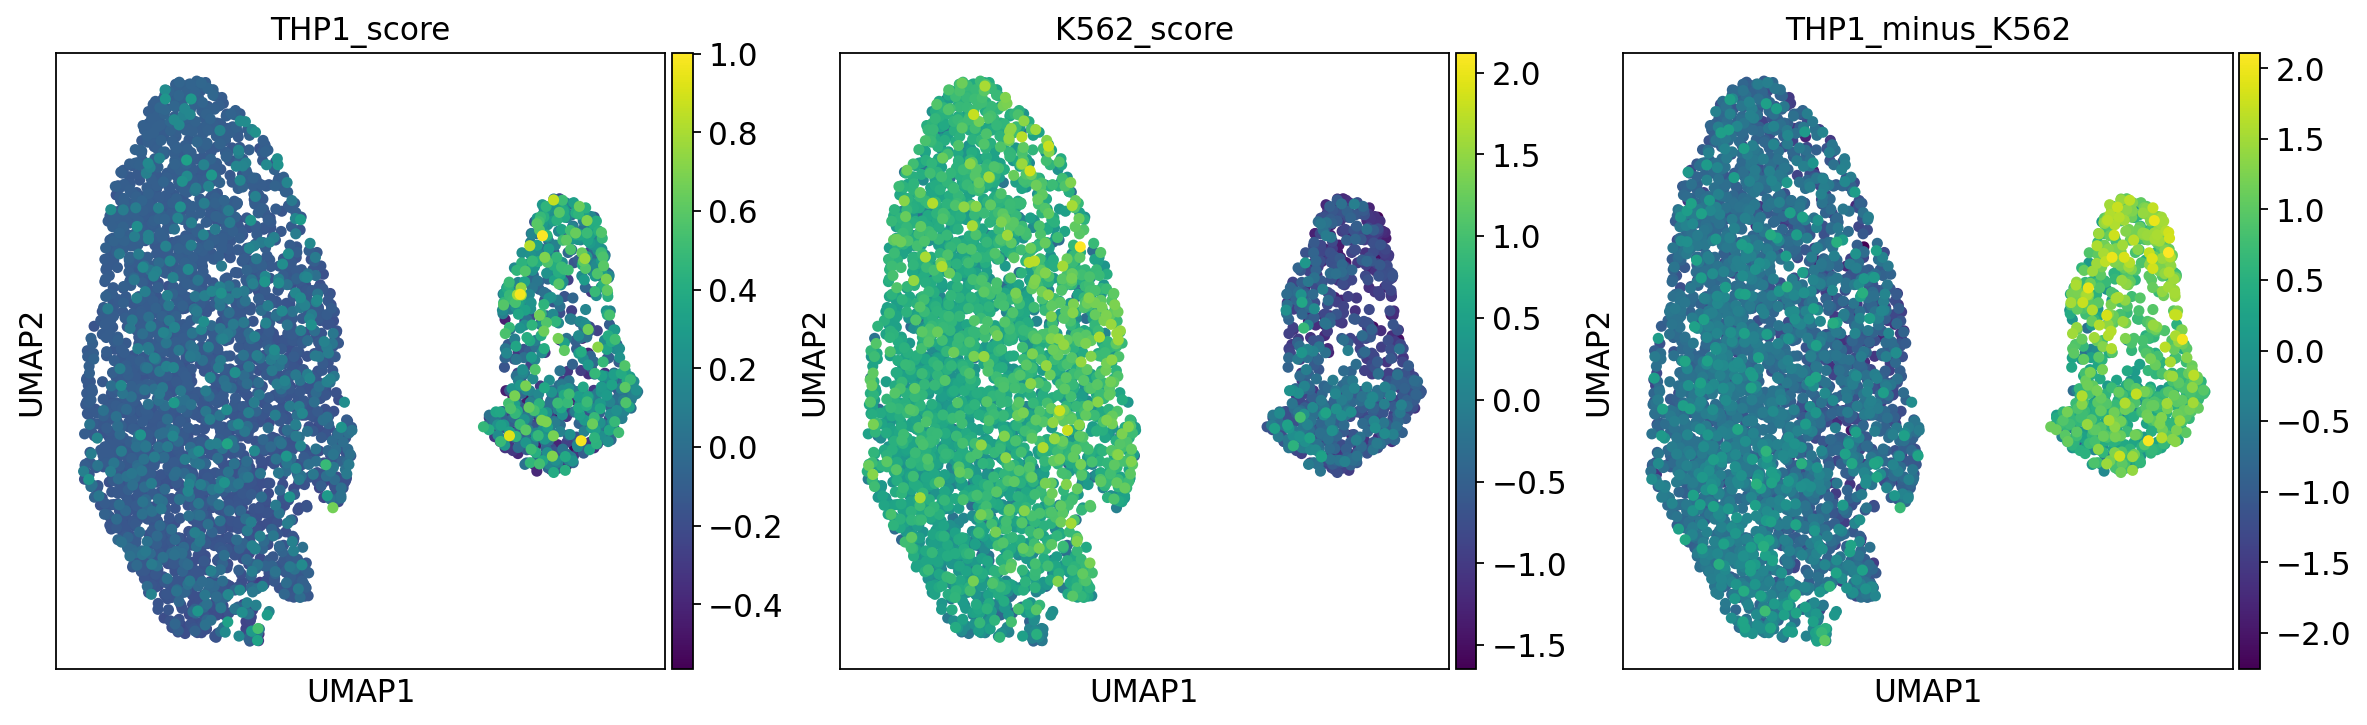

In [346]:
# -----------------------------
# 1) Marker lists (yours)
# -----------------------------
thp1_markers = [
    "CD14","CD11b","CD68","CD33","CD163","CD80","HLA-DR","FCGR1A","MAFB","TNFAIP2"
]
k562_markers = [
    "CD235a","CD71","CD34","CD43","CD36","GATA1","HBG1","CD69","IRF1","BCR-ABL"
]

# -----------------------------
# 2) Alias -> gene symbol fixes (edit if your var_names differ)
# -----------------------------
alias_map = {
    "CD11b": "ITGAM",
    "CD235a": "GYPA",
    "CD71": "TFRC",
    "HLA-DR": "HLA-DRA",   # you can also add HLA-DRB1 as separate marker if present
    "BCR-ABL": None,       # fusion; handle below
}

def _normalize_gene(g):
    return alias_map.get(g, g)

def _present_genes(genes, adata):
    # normalize
    g2 = []
    for g in genes:
        ng = _normalize_gene(g)
        if ng is None:
            continue
        g2.append(ng)

    # handle BCR-ABL as (BCR, ABL1) if present
    if "BCR" in adata.var_names and "ABL1" in adata.var_names:
        # optional: include both as a proxy
        pass

    # keep those present
    present = [g for g in g2 if g in adata.var_names]
    missing = sorted(set(g2) - set(present))
    return present, missing

thp1_present, thp1_missing = _present_genes(thp1_markers, adata_hvg)
k562_present, k562_missing = _present_genes(k562_markers, adata_hvg)

print("THP1 present:", thp1_present)
print("THP1 missing:", thp1_missing)
print("K562 present:", k562_present)
print("K562 missing:", k562_missing)

# Optional: add BCR and ABL1 if both exist and you want that proxy
if ("BCR" in adata_hvg.var_names) and ("ABL1" in adata_hvg.var_names):
    # only add if not already included
    if "BCR" not in k562_present:  k562_present.append("BCR")
    if "ABL1" not in k562_present: k562_present.append("ABL1")

# -----------------------------
# 3) Score modules (Seurat-style)
#    - use_raw=True if you have adata_hvg.raw set to log-normalized counts you trust
# -----------------------------
sc.tl.score_genes(adata_hvg, thp1_present, score_name="THP1_score", use_raw=False, layer="log1p")
sc.tl.score_genes(adata_hvg, k562_present, score_name="K562_score", use_raw=False, layer="log1p")

# A simple combined discriminator
adata_hvg.obs["THP1_minus_K562"] = adata_hvg.obs["THP1_score"] - adata_hvg.obs["K562_score"]

# -----------------------------
# 4) Diagnostics: compare marker scores to current cell_type labels
# -----------------------------
# If cell_type labels have already been assigned:
if "cell_type" in adata_hvg.obs:
    print("\nMean scores by cell_type:")
    display(adata_hvg.obs.groupby("cell_type")[["THP1_score","K562_score","THP1_minus_K562"]].mean())

# Visualize
sc.pl.violin(
    adata_hvg,
    keys=["THP1_score","K562_score","THP1_minus_K562"],
    groupby="cell_type" if "cell_type" in adata_hvg.obs else None,
    rotation=45,
    stripplot=False,
)

# Optional: UMAP colored by scores if you have X_umap
if "X_umap" in adata_hvg.obsm:
    sc.pl.umap(adata_hvg, color=["THP1_score","K562_score","THP1_minus_K562"], size=100)


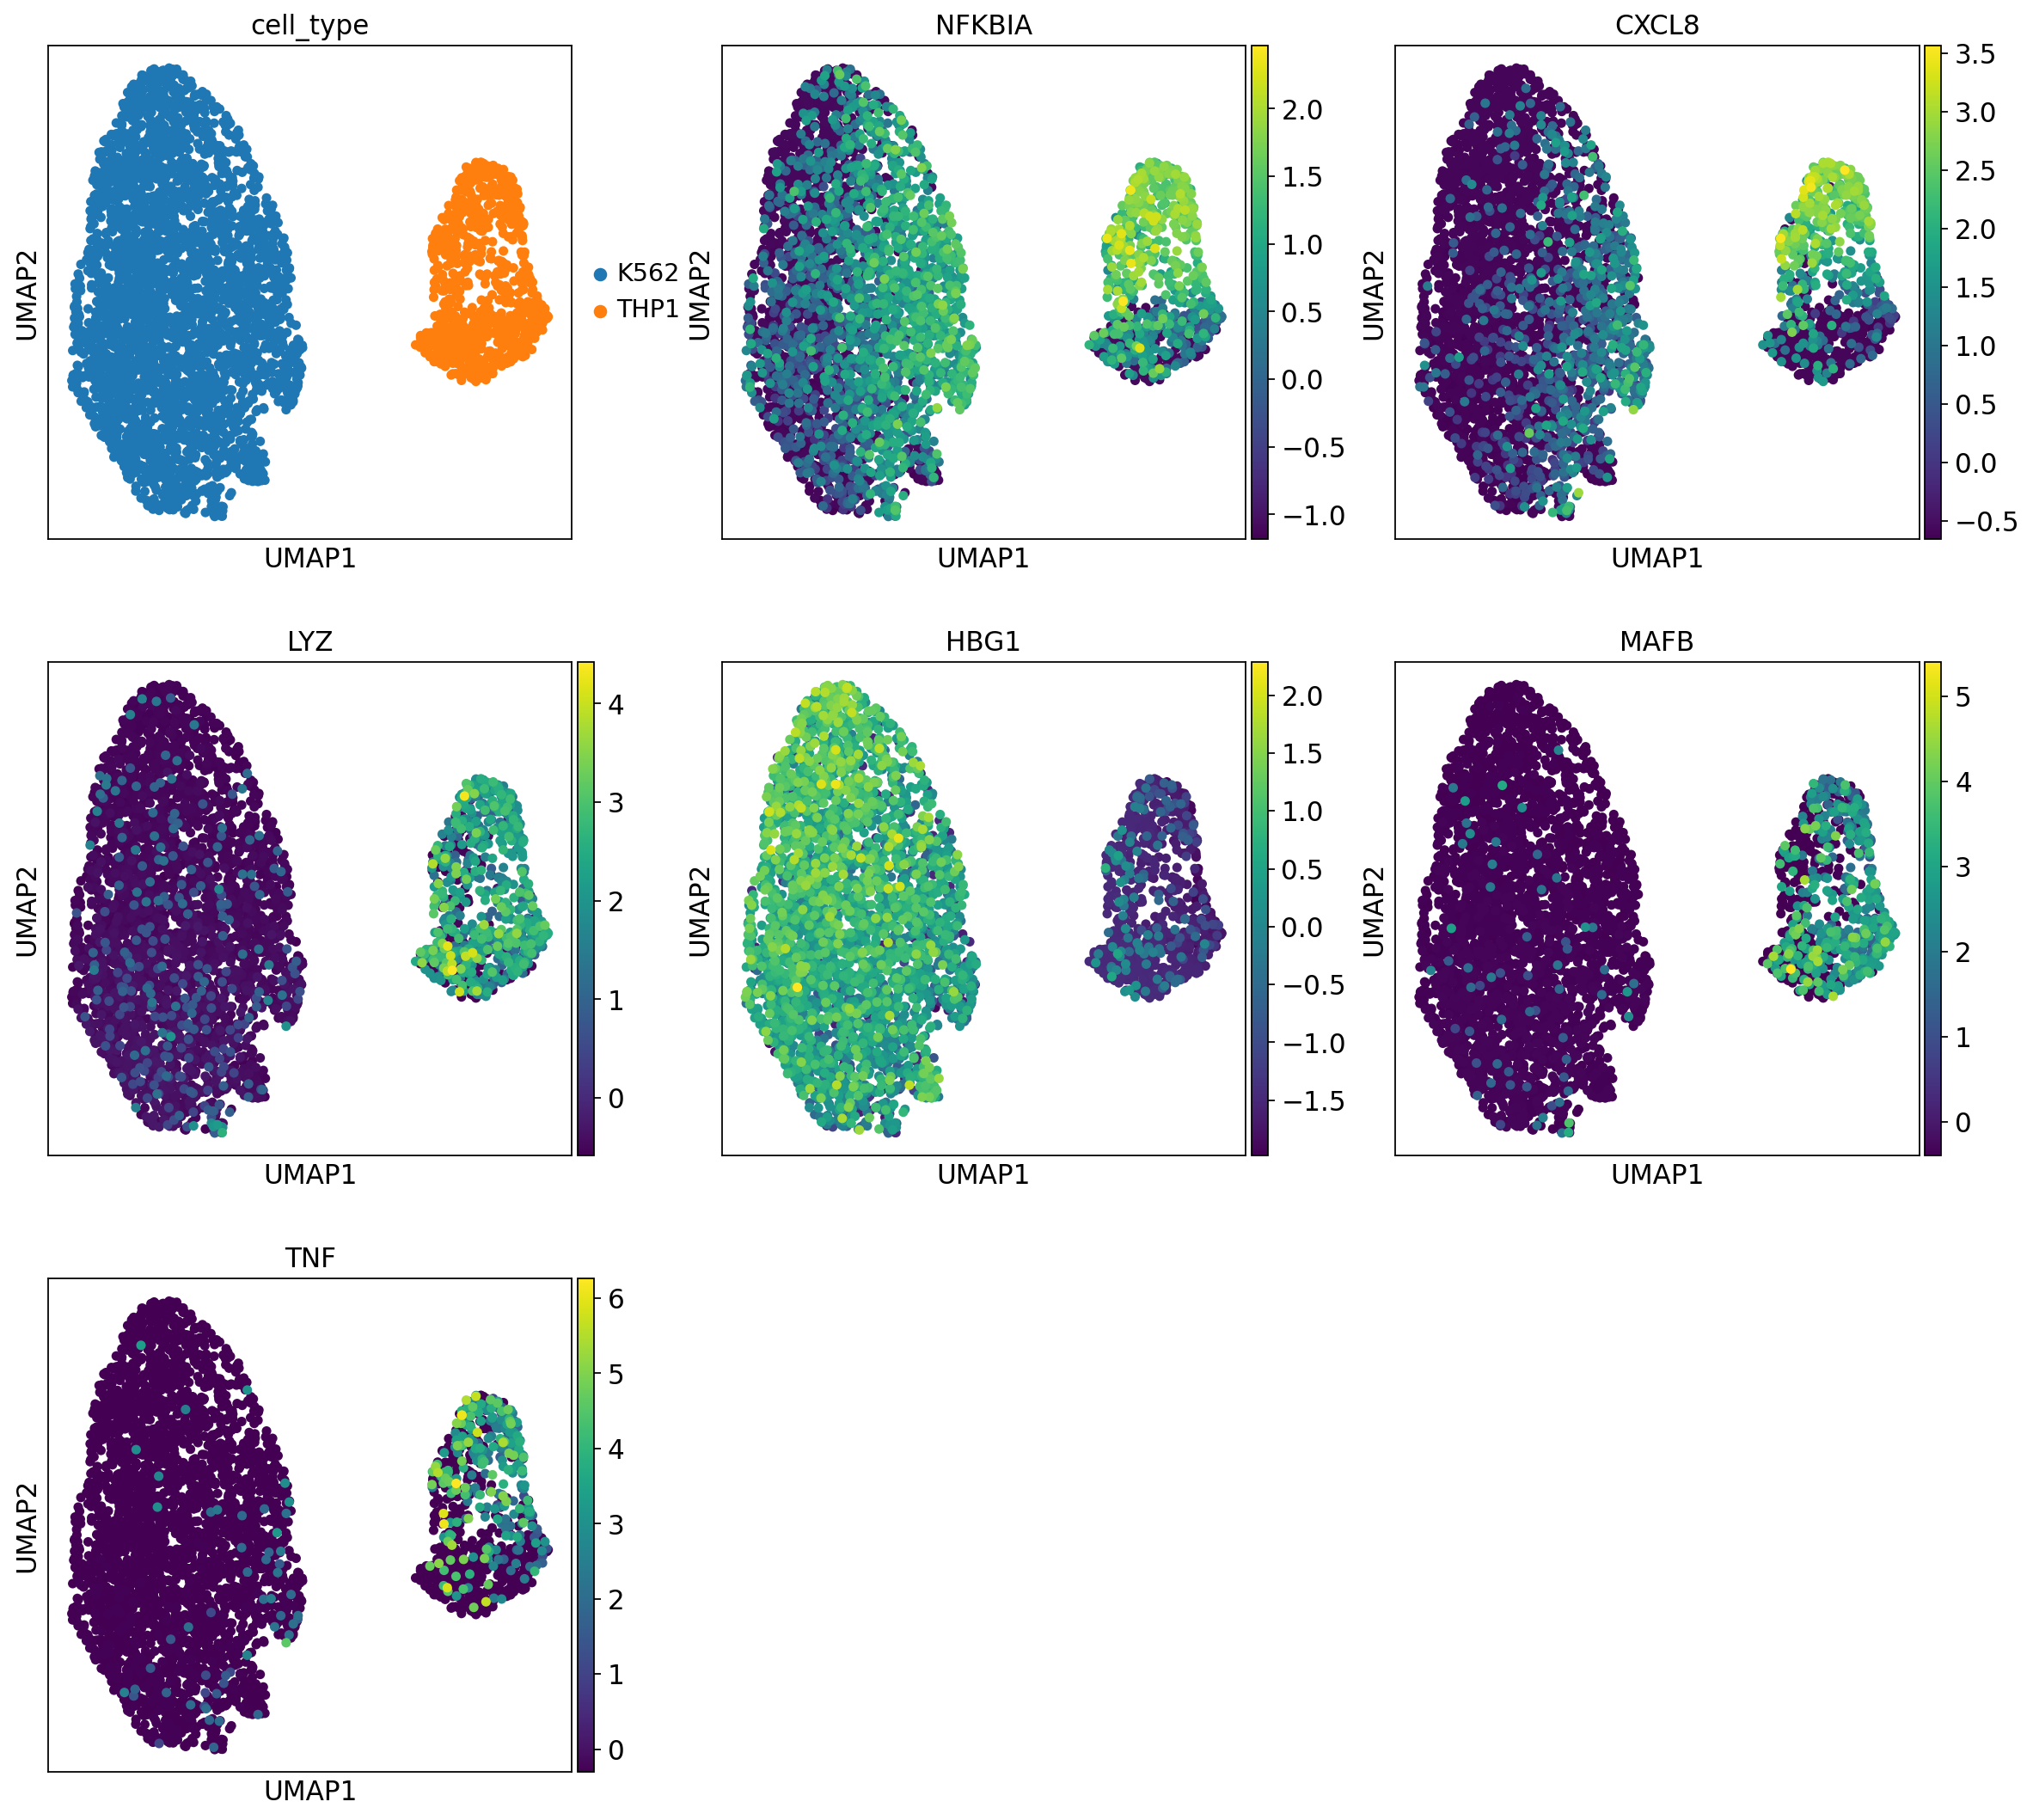

In [354]:
def RenameCluster(x):
    if x=='0': return 'K562'
    if x=='1': return 'THP1'


adata_hvg.obs['cell_type'] = [RenameCluster(x) for x in adata_hvg.obs['leiden_unintegrated']]

lineage_marker_genes = thp1_present + k562_present
sc.pl.umap(adata_hvg, color=['cell_type'] + lineage_marker_genes + ['TNF'], ncols=3, cmap='viridis', gene_symbols=None, size=100)


# Save single-cell AnnData object

In [349]:
adata = adata[adata_hvg.obs.index, :]
adata.obsp = adata_hvg.obsp.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obs = adata_hvg.obs.copy()

print(adata)
print(adata_hvg)

cp.io.validate_preprocessed_adata(
    adata,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)
cp.io.validate_preprocessed_adata(
    adata_hvg,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)

adata.write_h5ad('../output/adata_full.chk0.h5ad')
adata_hvg.write_h5ad('../output/adata_hvg.chk0.h5ad')


AnnData object with n_obs × n_vars = 3915 × 21693
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_unintegrated', 'THP1_score', 'K562_score', 'THP1_minus_K562', 'cell_type'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', 'cpm', 'log1p'
    obsp: 'distances', 'connectivities'
AnnData object with n_obs × n_vars = 3915 × 1994
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_g